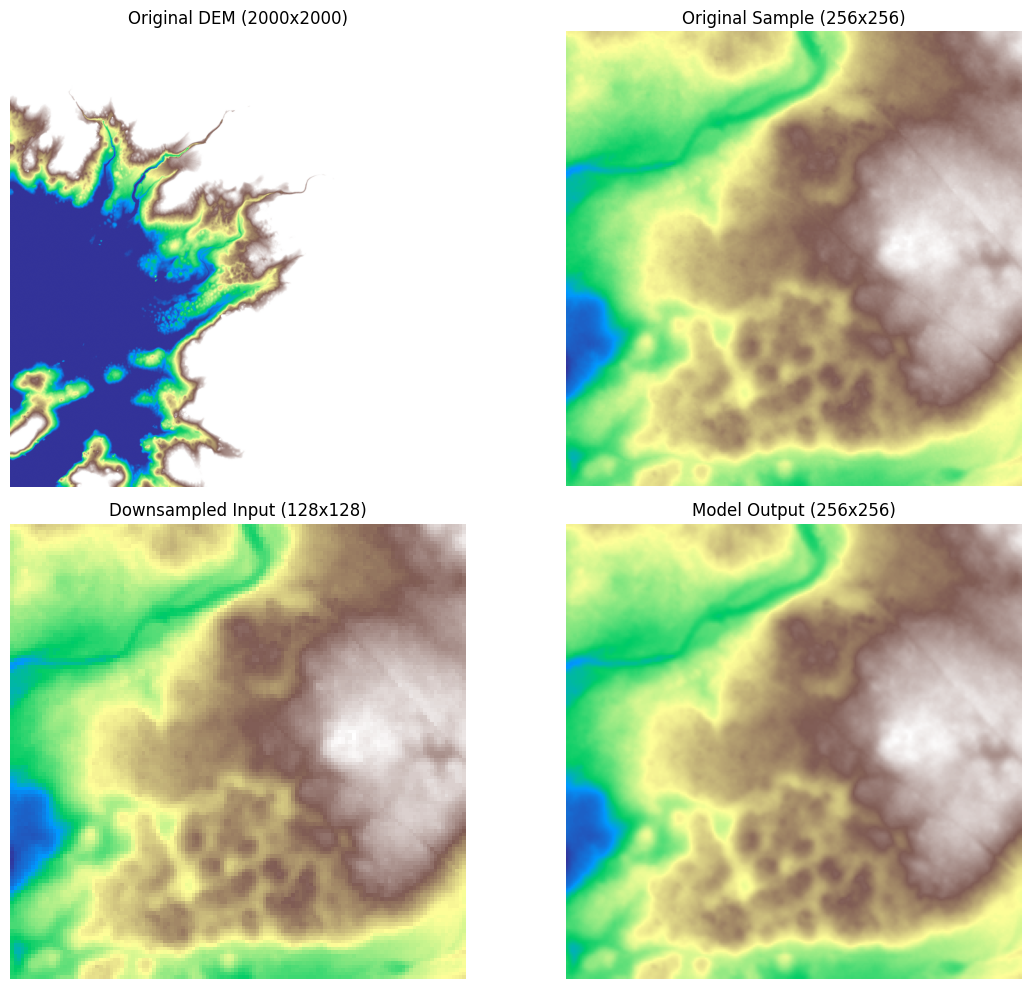

In [2]:

import matplotlib.pyplot as plt
import rasterio

# Read full 2000x2000 DEM
with rasterio.open("SierraNevada_DEM/USGS_OPR_CA_SierraNevada_B22_be_11SKA7089.tif") as src:
    full_dem = src.read(1, masked=True)
# Read original 256 sample 256x256 DEM
with rasterio.open("output/Terrain_Original_256.tif") as src:
    original = src.read(1, masked=True)
# Read low resolution downsample input 128x128 DEM
with rasterio.open("output/Terrain_Input_128.tif") as src:
    lr = src.read(1, masked=True)
# Read model output upsample 256x256 DEM
with rasterio.open("output/Terrain_SR_256.tif") as src:
    sr = src.read(1, masked=True)


# Display all four images
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

images = [
    (full_dem, "Original DEM (2000x2000)"),
    (original, "Original Sample (256x256)"),
    (lr, "Downsampled Input (128x128)"),
    (sr, "Model Output (256x256)")
]

# Use the same elevation color scale for comparison
vmin = original.min()
vmax = original.max()

for ax, (image, title) in zip(axes.flat, images):

    ax.imshow(
        image,
        cmap="terrain",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title)
    ax.axis("off")


plt.tight_layout()
plt.show()
